### Create Circuit


In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# Create a circuit with one qubit and one classical bit
qc = QuantumCircuit(1, 1)

# Apply a Hadamard gate
qc.h(0)

# Measure the qubit
qc.measure(0, 0)

# Display the circuit
print(qc.draw(output="text"))

     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


In [6]:
simulator = AerSimulator()

job = simulator.run(qc, shots=1000)

result = job.result()

counts = result.get_counts()

print(counts)

{'0': 490, '1': 510}


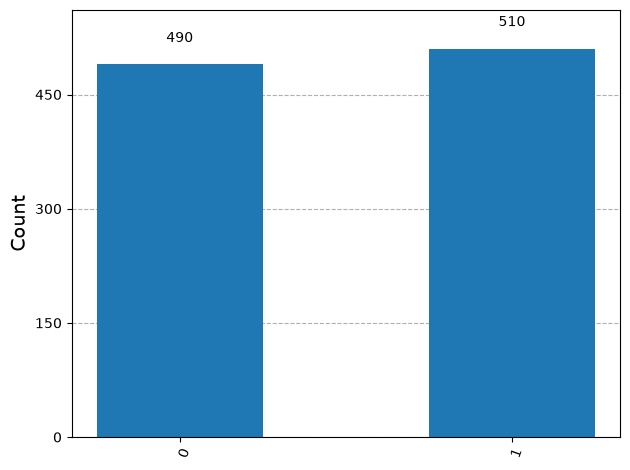

In [9]:
%matplotlib inline
import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram

plot_histogram(counts)
plt.show()

### Bell State Simulation

In [5]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

def create_bell_circuit():

    # Two qubits and two classical bits
    qc = QuantumCircuit(2, 2)

    # Put the first qubit into superposition
    qc.h(0)

    # Entangle the two qubits
    qc.cx(0, 1)

    # Measure both qubits
    qc.measure([0, 1], [0, 1])

    return qc


bell_circuit = create_bell_circuit()

print(bell_circuit.draw())

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


In [6]:
simulator = AerSimulator()

compiled_circuit = transpile(
    bell_circuit,
    simulator
)

job = simulator.run(
    compiled_circuit,
    shots=10000
)

result = job.result()

bell_counts = result.get_counts()

print("Bell-state measurement results:")
print(bell_counts)

Bell-state measurement results:
{'11': 5034, '00': 4966}


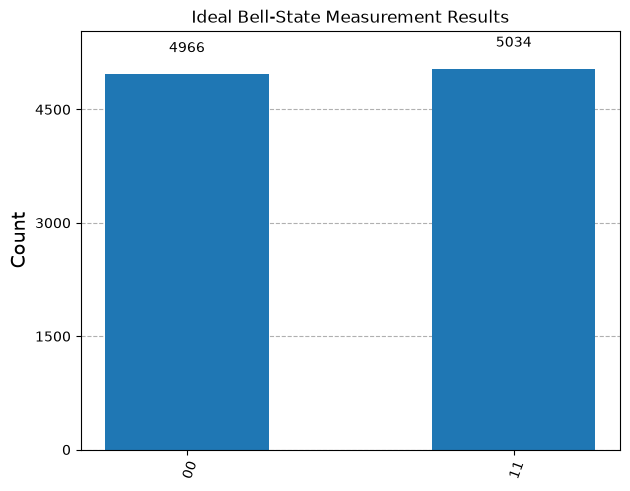

In [9]:
%matplotlib inline
plot_histogram(bell_counts)
plt.title("Ideal Bell-State Measurement Results")
plt.show()

### Introduction of Quantum Noise

In [11]:
from qiskit_aer.noise import NoiseModel, depolarizing_error

In [13]:
def create_noise_model(p):

    noise_model = NoiseModel()

    # Single-qubit depolarizing error
    error_1q = depolarizing_error(p, 1)

    # Two-qubit depolarizing error
    error_2q = depolarizing_error(p, 2)

    # Apply errors after the corresponding gates
    noise_model.add_all_qubit_quantum_error(
        error_1q,
        ["h"]
    )

    noise_model.add_all_qubit_quantum_error(
        error_2q,
        ["cx"]
    )

    return noise_model

In [15]:
def simulate_noisy_bell(p, shots=10000):

    # Create the circuit
    circuit = create_bell_circuit()

    # Create the noise model
    noise_model = create_noise_model(p)

    # Configure the simulator
    simulator = AerSimulator(
        noise_model=noise_model
    )

    # Compile for this simulator
    compiled = transpile(
        circuit,
        simulator,
        optimization_level=0
    )

    # Execute the circuit
    result = simulator.run(
        compiled,
        shots=shots
    ).result()

    # Return measurement counts
    return result.get_counts()

{'00': 4851, '11': 4878, '10': 139, '01': 132}


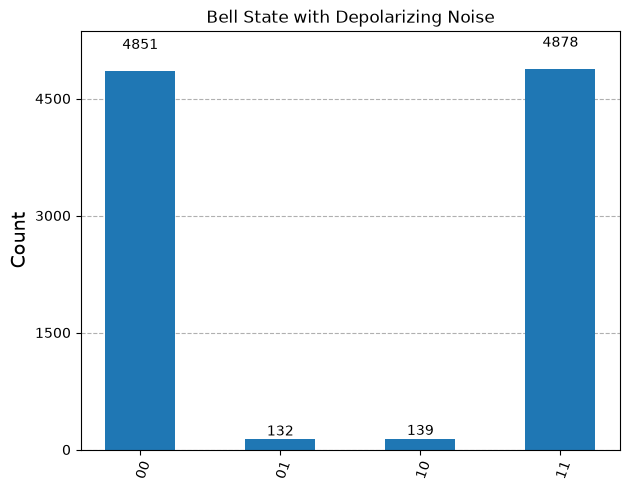

In [17]:
noisy_counts = simulate_noisy_bell(0.05)

print(noisy_counts)

plot_histogram(noisy_counts)
plt.title("Bell State with Depolarizing Noise")
plt.show()

### Calculation of Bell State Fidelity

In [19]:
from qiskit.quantum_info import (
    Statevector,
    state_fidelity
)

In [21]:
def calculate_bell_fidelity(p):

    # Create a Bell-state circuit without measurements
    qc = QuantumCircuit(2)

    qc.h(0)
    qc.cx(0, 1)

    # Save the final density matrix
    qc.save_density_matrix()

    # Create the noise model
    noise_model = create_noise_model(p)

    # Use the density-matrix simulation method
    simulator = AerSimulator(
        method="density_matrix",
        noise_model=noise_model
    )

    # Compile and simulate
    compiled = transpile(
        qc,
        simulator,
        optimization_level=0
    )

    result = simulator.run(
        compiled,
        shots=1
    ).result()

    # Retrieve the simulated quantum state
    noisy_state = result.data(0)["density_matrix"]

    # Construct the ideal Bell state
    ideal_circuit = QuantumCircuit(2)

    ideal_circuit.h(0)
    ideal_circuit.cx(0, 1)

    ideal_state = Statevector.from_instruction(
        ideal_circuit
    )

    # Calculate fidelity
    fidelity = state_fidelity(
        ideal_state,
        noisy_state
    )

    return float(fidelity)

In [23]:
for p in [0.00, 0.01, 0.05, 0.10, 0.20]:

    fidelity = calculate_bell_fidelity(p)

    print(
        f"Noise strength = {p:.2f}, "
        f"Fidelity = {fidelity:.4f}"
    )

Noise strength = 0.00, Fidelity = 1.0000
Noise strength = 0.01, Fidelity = 0.9876
Noise strength = 0.05, Fidelity = 0.9387
Noise strength = 0.10, Fidelity = 0.8800
Noise strength = 0.20, Fidelity = 0.7700


### Generate graphs

In [32]:
import numpy as np
noise_values = np.linspace(0, 0.20, 21)

fidelity_values = []

In [33]:
for p in noise_values:

    fidelity = calculate_bell_fidelity(p)

    fidelity_values.append(fidelity)

    print(
        f"Noise = {p:.3f}, "
        f"Fidelity = {fidelity:.5f}"
    )

Noise = 0.000, Fidelity = 1.00000
Noise = 0.010, Fidelity = 0.98755
Noise = 0.020, Fidelity = 0.97520
Noise = 0.030, Fidelity = 0.96295
Noise = 0.040, Fidelity = 0.95080
Noise = 0.050, Fidelity = 0.93875
Noise = 0.060, Fidelity = 0.92680
Noise = 0.070, Fidelity = 0.91495
Noise = 0.080, Fidelity = 0.90320
Noise = 0.090, Fidelity = 0.89155
Noise = 0.100, Fidelity = 0.88000
Noise = 0.110, Fidelity = 0.86855
Noise = 0.120, Fidelity = 0.85720
Noise = 0.130, Fidelity = 0.84595
Noise = 0.140, Fidelity = 0.83480
Noise = 0.150, Fidelity = 0.82375
Noise = 0.160, Fidelity = 0.81280
Noise = 0.170, Fidelity = 0.80195
Noise = 0.180, Fidelity = 0.79120
Noise = 0.190, Fidelity = 0.78055
Noise = 0.200, Fidelity = 0.77000


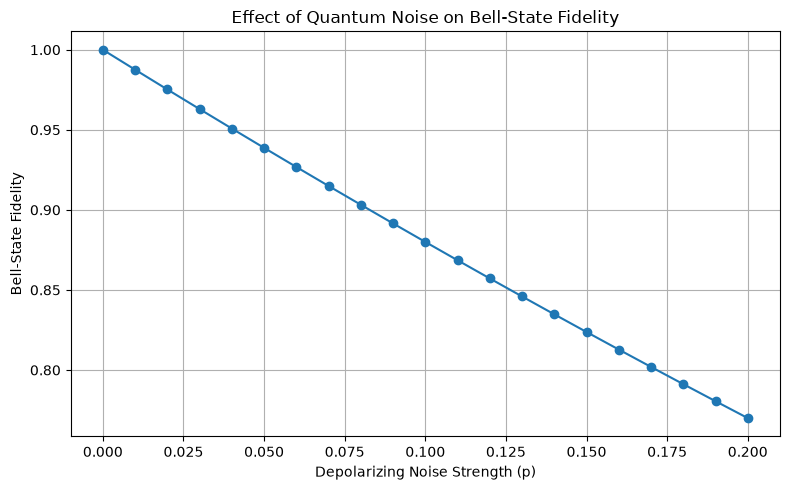

In [34]:
%matplotlib inline
plt.figure(figsize=(8, 5))

plt.plot(
    noise_values,
    fidelity_values,
    marker="o"
)

plt.xlabel("Depolarizing Noise Strength (p)")
plt.ylabel("Bell-State Fidelity")

plt.title("Effect of Quantum Noise on Bell-State Fidelity")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "bell_fidelity_vs_noise.png",
    dpi=300
)

plt.show()

### Implement Grover's Search Algorithm

In [36]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator


def create_grover_circuit():

    qc = QuantumCircuit(2, 2)

    # Step 1: Create a uniform superposition
    qc.h([0, 1])

    # Step 2: Oracle marking the state |11>
    qc.cz(0, 1)

    # Step 3: Grover diffusion operator
    qc.h([0, 1])

    qc.x([0, 1])

    qc.h(1)
    qc.cx(0, 1)
    qc.h(1)

    qc.x([0, 1])

    qc.h([0, 1])

    # Step 4: Measure
    qc.measure([0, 1], [0, 1])

    return qc


grover_circuit = create_grover_circuit()

print(grover_circuit.draw(output="text"))

     ┌───┐   ┌───┐┌───┐          ┌───┐┌───┐     ┌─┐   
q_0: ┤ H ├─■─┤ H ├┤ X ├───────■──┤ X ├┤ H ├─────┤M├───
     ├───┤ │ ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐└╥┘┌─┐
q_1: ┤ H ├─■─┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├─╫─┤M├
     └───┘   └───┘└───┘└───┘└───┘└───┘└───┘└───┘ ║ └╥┘
c: 2/════════════════════════════════════════════╩══╩═
                                                 0  1 


{'11': 10000}


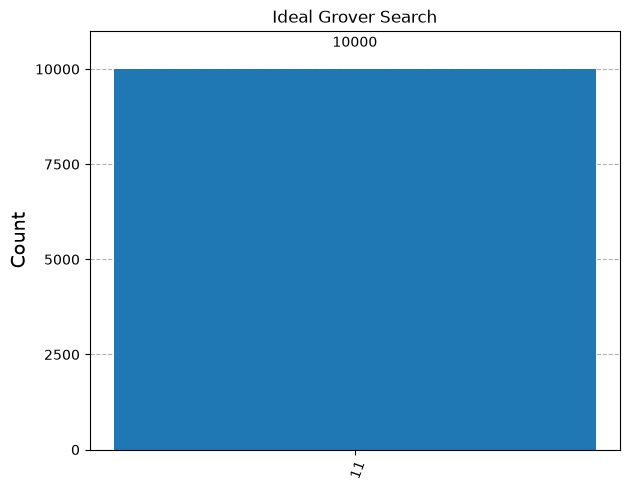

In [38]:
simulator = AerSimulator()

compiled = transpile(
    grover_circuit,
    simulator
)

result = simulator.run(
    compiled,
    shots=10000
).result()

grover_counts = result.get_counts()

print(grover_counts)

plot_histogram(grover_counts)

plt.title("Ideal Grover Search")
plt.show()

### Investigate Noise In Grover's Algorithm

In [40]:
def simulate_noisy_grover(p, shots=10000):

    circuit = create_grover_circuit()

    noise_model = create_noise_model(p)

    simulator = AerSimulator(
        noise_model=noise_model
    )

    compiled = transpile(
        circuit,
        simulator,
        optimization_level=0
    )

    result = simulator.run(
        compiled,
        shots=shots
    ).result()

    counts = result.get_counts()

    return counts

In [42]:
def calculate_grover_success_probability(
    p,
    shots=10000
):

    counts = simulate_noisy_grover(
        p,
        shots
    )

    successes = counts.get("11", 0)

    probability = successes / shots

    return probability

In [44]:
for p in [0.00, 0.01, 0.05, 0.10, 0.20]:

    success_probability = (
        calculate_grover_success_probability(p)
    )

    print(
        f"Noise = {p:.2f}, "
        f"Success probability = "
        f"{success_probability:.4f}"
    )

Noise = 0.00, Success probability = 1.0000
Noise = 0.01, Success probability = 0.8876
Noise = 0.05, Success probability = 0.5743
Noise = 0.10, Success probability = 0.3805
Noise = 0.20, Success probability = 0.2733


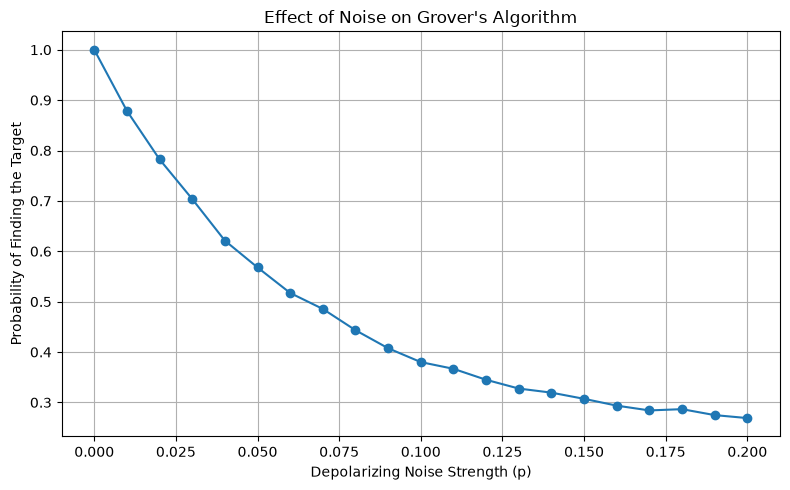

In [46]:
noise_values = np.linspace(0, 0.20, 21)

grover_success_values = []

for p in noise_values:

    probability = (
        calculate_grover_success_probability(
            p,
            shots=10000
        )
    )

    grover_success_values.append(probability)


plt.figure(figsize=(8, 5))

plt.plot(
    noise_values,
    grover_success_values,
    marker="o"
)

plt.xlabel("Depolarizing Noise Strength (p)")

plt.ylabel("Probability of Finding the Target")

plt.title("Effect of Noise on Grover's Algorithm")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "grover_success_vs_noise.png",
    dpi=300
)

plt.show()

### Comparison of Both Quantum Circuits

In [49]:
import pandas as pd
noise_values = np.linspace(0, 0.20, 21)

results_data = []

for p in noise_values:

    bell_fidelity = calculate_bell_fidelity(p)

    grover_success = (
        calculate_grover_success_probability(
            p,
            shots=10000
        )
    )

    results_data.append({
        "Noise Strength": p,
        "Bell-State Fidelity": bell_fidelity,
        "Grover Success Probability": grover_success
    })


results_df = pd.DataFrame(results_data)

print(results_df)

    Noise Strength  Bell-State Fidelity  Grover Success Probability
0             0.00              1.00000                      1.0000
1             0.01              0.98755                      0.8857
2             0.02              0.97520                      0.7845
3             0.03              0.96295                      0.7045
4             0.04              0.95080                      0.6304
5             0.05              0.93875                      0.5745
6             0.06              0.92680                      0.5197
7             0.07              0.91495                      0.4747
8             0.08              0.90320                      0.4494
9             0.09              0.89155                      0.4211
10            0.10              0.88000                      0.3807
11            0.11              0.86855                      0.3581
12            0.12              0.85720                      0.3469
13            0.13              0.84595         

In [50]:
# results_df.to_csv(
#    "quantum_simulation_results.csv",
#    index=False
#)

#print("Results saved successfully!")

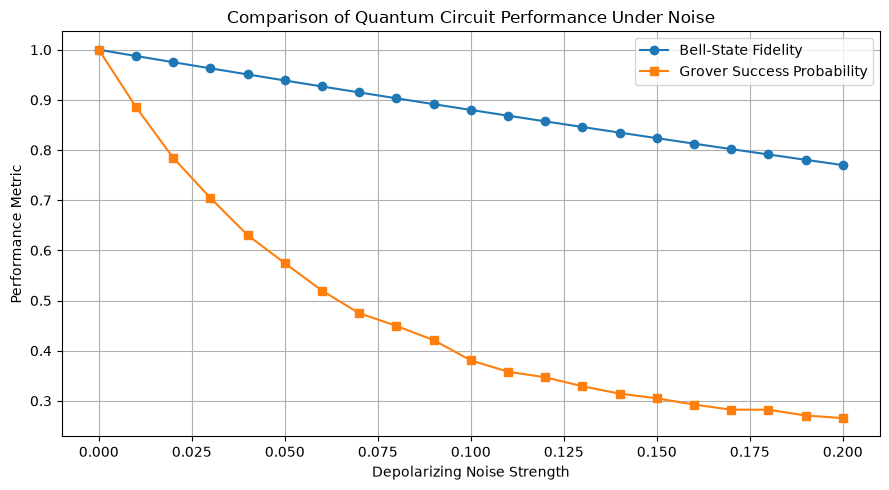

In [52]:
plt.figure(figsize=(9, 5))

plt.plot(
    results_df["Noise Strength"],
    results_df["Bell-State Fidelity"],
    marker="o",
    label="Bell-State Fidelity"
)

plt.plot(
    results_df["Noise Strength"],
    results_df["Grover Success Probability"],
    marker="s",
    label="Grover Success Probability"
)

plt.xlabel("Depolarizing Noise Strength")

plt.ylabel("Performance Metric")

plt.title("Comparison of Quantum Circuit Performance Under Noise")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "quantum_circuit_comparison.png",
    dpi=300
)

plt.show()

### Testing Different Circuit depths

In [54]:
def create_depth_test_circuit(depth):

    qc = QuantumCircuit(2)

    # Prepare the Bell state
    qc.h(0)
    qc.cx(0, 1)

    # Add repeated pairs of CNOT gates
    for _ in range(depth):

        qc.cx(0, 1)
        qc.cx(0, 1)

    # Save the state before measurement
    qc.save_density_matrix()

    return qc

In [56]:
def calculate_depth_fidelity(
    depth,
    p
):

    qc = create_depth_test_circuit(depth)

    noise_model = create_noise_model(p)

    simulator = AerSimulator(
        method="density_matrix",
        noise_model=noise_model
    )

    compiled = transpile(
        qc,
        simulator,
        optimization_level=0
    )

    result = simulator.run(
        compiled,
        shots=1
    ).result()

    noisy_state = result.data(0)["density_matrix"]

    ideal_qc = QuantumCircuit(2)

    ideal_qc.h(0)
    ideal_qc.cx(0, 1)

    ideal_state = Statevector.from_instruction(
        ideal_qc
    )

    return float(
        state_fidelity(
            ideal_state,
            noisy_state
        )
    )

In [58]:
depths = [0, 1, 2, 3, 4, 5, 10]

p = 0.02

depth_fidelities = []

for depth in depths:

    fidelity = calculate_depth_fidelity(
        depth,
        p
    )

    depth_fidelities.append(fidelity)

    print(
        f"Depth parameter = {depth}, "
        f"Fidelity = {fidelity:.5f}"
    )

Depth parameter = 0, Fidelity = 0.97520
Depth parameter = 1, Fidelity = 0.94648
Depth parameter = 2, Fidelity = 0.91890
Depth parameter = 3, Fidelity = 0.89241
Depth parameter = 4, Fidelity = 0.86697
Depth parameter = 5, Fidelity = 0.84254
Depth parameter = 10, Fidelity = 0.73415


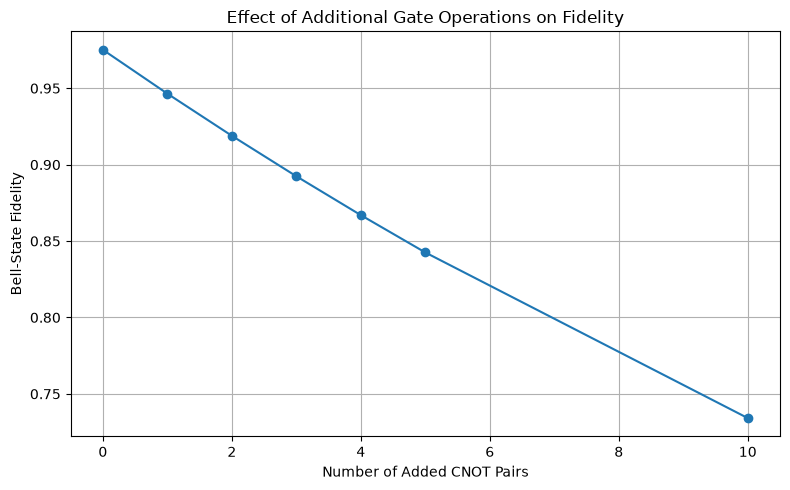

In [60]:
plt.figure(figsize=(8, 5))

plt.plot(
    depths,
    depth_fidelities,
    marker="o"
)

plt.xlabel("Number of Added CNOT Pairs")

plt.ylabel("Bell-State Fidelity")

plt.title("Effect of Additional Gate Operations on Fidelity")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "bell_fidelity_vs_depth.png",
    dpi=300
)

plt.show()